# Влияние числа моделей в GradientBoostingClassifier

**Предмет:** Основы машинного обучения

**Студент:** Волгина Анастасия, 5030102/30101 

**Цель работы:** изучить, как количество базовых моделей (деревьев решений) в градиентном бустинге влияет на качество классификации и склонность к переобучению, время обучения, и важность признаков для классификации, а также исследовать механизм ранней остановки для автоматического подбора оптимального числа деревьев.

**План:**
1. Теория
2. Описание используемых датасетов, загрузка и разбиение данных
3. Анализ кривых обучения
4. Анализ времени обучения
5. Механизм ранней остановки (Early Stopping)
6. Анализ важности признаков (Feature Importance)
7. Выводы

## 1. Теория

### 1.1. Градиентный бустинг

**Градиентный бустинг** (gradient boosting) - это метод ансамблевого обучения, в котором модели строятся **последовательно**, и каждая следующая модель пытается исправить ошибки предыдущих. Бустинг обучает деревья одно за другим, и итоговое предсказание представляет собой их **взвешенную сумму**.

Ансамбль из $M$ моделей задаёт предсказание вида:

$$
F_M(x) = F_0(x) + \sum_{m=1}^{M} \nu \cdot h_m(x),
$$

где:
- $F_0(x)$ - начальное приближение (обычно для классификации берется логарифм отношения шансов);
- $h_m(x)$ - $m$-я базовая модель (в `GradientBoostingClassifier` — регрессионное дерево решений);
- $\nu$ - скорость обучения (`learning_rate`), масштабирующая вклад каждого дерева;
- $M$ - число базовых моделей (`n_estimators`).

Ключевая идея градиентного бустинга - рассматривать ансамбль $F(x)$ как **параметр** в функциональном пространстве и минимизировать эмпирический риск

$$
\mathcal{L}(F) = \sum_{i=1}^{N} \ell(y_i, F(x_i))
$$

методом градиентного спуска. На каждом шаге $m$:

1. Вычисляются **антиградиенты** функции потерь по текущим предсказаниям:
$$
r_{im} = -\left. \frac{\partial \ell(y_i, F(x_i))}{\partial F(x_i)} \right|_{F = F_{m-1}}, \quad i = 1, \dots, N.
$$
Эти величины называются **псевдоостатками** (pseudo-residuals) и играют роль целевой переменной для следующего дерева.

2. Обучается базовое дерево $h_m(x)$ на признаках $x_i$ с целевой переменной $r_{im}$ (дерево регрессии, критерий обычно - минимизация среднеквадратичной ошибки MSE).

3. Вычисляется оптимальный коэффициент $\gamma_m$ (или несколько - по листьям дерева) для минимизации потерь, и модель обновляется:
$$
F_m(x) = F_{m-1}(x) + \nu \cdot \gamma_m \cdot h_m(x).
$$

Для задачи **классификации** (бинарной или многоклассовой) в `sklearn` используется логистическая функция потерь (deviance), и на каждом шаге обучается по одному дереву на каждый класс.


### 1.2. Ранняя остановка (Early Stopping)

Механизм **Early Stopping**, реализованный в `sklearn`, позволяет автоматически определить оптимальное число деревьев, не перебирая $M$ вручную. Как он работает:
1. Задаем заведомо большое значение `n_estimators` (например, 1000).
2. Активируем механизм через параметр `n_iter_no_change`.
3. Алгоритм внутри разбивает обучающую выборку на train и validation (параметр `validation_fraction`, по умолчанию 0.1).
4. После каждой итерации он проверяет значение функции потерь на валидационной выборке.
5. Если Loss не улучшается на протяжении `n_iter_no_change` итераций подряд, обучение останавливается досрочно. 

Фактическое число деревьев, которое успело построиться, сохраняется в атрибуте `n_estimators_`.

Это даёт сразу два преимущества: **(а)** защита от переобучения без явного подбора $M$; **(б)** экономия времени вычислений, поскольку «лишние» деревья не строятся.

## 2. Описание используемых датасетов, загрузка и разбиение данных

Для всестороннего исследования влияния параметра `n_estimators` мы будем использовать два набора данных с разными свойствами. Это позволит показать, как ведет себя алгоритм на «реальных» чистых данных и на данных с искусственным шумом.

### Датасет 1: Breast Cancer
*   **Тип задачи:** Бинарная классификация (злокачественная / доброкачественная опухоль).
*   **Источник:** Встроенный датасет `sklearn.datasets.load_breast_cancer`.
*   **Размер:** 569 объектов, 30 числовых признаков.

### Датасет 2: Синтетические данные с шумом (Make Classification)
*   **Тип задачи:** Бинарная классификация.
*   **Источник:** Генератор `sklearn.datasets.make_classification`.
*   **Размер:** 1000 объектов, 20 признаков (из них 10 информативных).
  
Параметр `flip_y=0.25` вносит 25% случайного шума в целевую переменную (метки классов частично перемешаны).


Разбиение на обучающую и тестовую выборки будем производить в пропорции 80/20. Чтобы сохранить исходное соотношение классов, применяем стратифицированное разбиение (`stratify`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

# датасет 1
data_bc = load_breast_cancer()
X_bc, y_bc = data_bc.data, data_bc.target

X_train_bc, X_test_bc, y_train_bc, y_test_bc = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=42, stratify=y_bc
)


# датасет 2
X_syn, y_syn = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_informative=10, 
    n_redundant=5, 
    n_classes=2,
    flip_y=0.25,
    shuffle=False,
    random_state=42
)

X_train_syn, X_test_syn, y_train_syn, y_test_syn = train_test_split(
    X_syn, y_syn, test_size=0.2, random_state=42, stratify=y_syn
)


print("Размеры:")
print(f"Breast Cancer: Train {X_train_bc.shape}, Test {X_test_bc.shape}")
print(f"Synthetic (noisy): Train {X_train_syn.shape}, Test {X_test_syn.shape}")

Размеры:
Breast Cancer: Train (455, 30), Test (114, 30)
Synthetic (noisy): Train (800, 20), Test (200, 20)


## 3. Анализ кривых обучения

Чтобы увидеть, как число деревьев влияет на модель, проведем следующий эксперимент:

Будем перебирать `n_estimators` в диапазоне от 2 до 200 и на каждом шаге измерять:
1.  `Train Accuracy` - метрика accuracy на обучающей выборке.
2.  `Test Accuracy` - метрика accuracy на тестовой выборке.
3. `Test Log Loss` - логарифмическая функция потерь на тестовой выборке.
   
Остальные гиперпараметры зафиксируем:
*   `learning_rate = 0.1`
*   `max_depth = 5`
*   `random_state = 42` (для воспроизводимости).

Графики зависимости метрик от `n_estimators` покажут нам момент наступления переобучения (когда тестовая метрика начинает ухудшаться).

In [2]:
n_estimators_list = [2, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 125, 150, 175, 200]

def evaluate_gradient_boosting(X_train, y_train, X_test, y_test):

    results = {
        'n_estimators': [],
        'train_acc': [],
        'test_acc': [],
        'test_logloss': [],
        'fit_time': []
    }
    
    for n in n_estimators_list:
        model = GradientBoostingClassifier(
            n_estimators=n, 
            learning_rate=0.1, 
            max_depth=5,
            random_state=42
        )
        
        start_time = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start_time
        
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        y_test_proba = model.predict_proba(X_test)[:, 1]
        
        results['n_estimators'].append(n)
        results['train_acc'].append(accuracy_score(y_train, y_train_pred))
        results['test_acc'].append(accuracy_score(y_test, y_test_pred))
        results['test_logloss'].append(log_loss(y_test, y_test_proba))
        results['fit_time'].append(fit_time)
        
    return pd.DataFrame(results)

print("Обучение моделей на Breast Cancer...")
df_results_bc = evaluate_gradient_boosting(X_train_bc, y_train_bc, X_test_bc, y_test_bc)

print("Обучение моделей на Synthetic Data...")
df_results_syn = evaluate_gradient_boosting(X_train_syn, y_train_syn, X_test_syn, y_test_syn)

print("Готово!")

Обучение моделей на Breast Cancer...
Обучение моделей на Synthetic Data...
Готово!


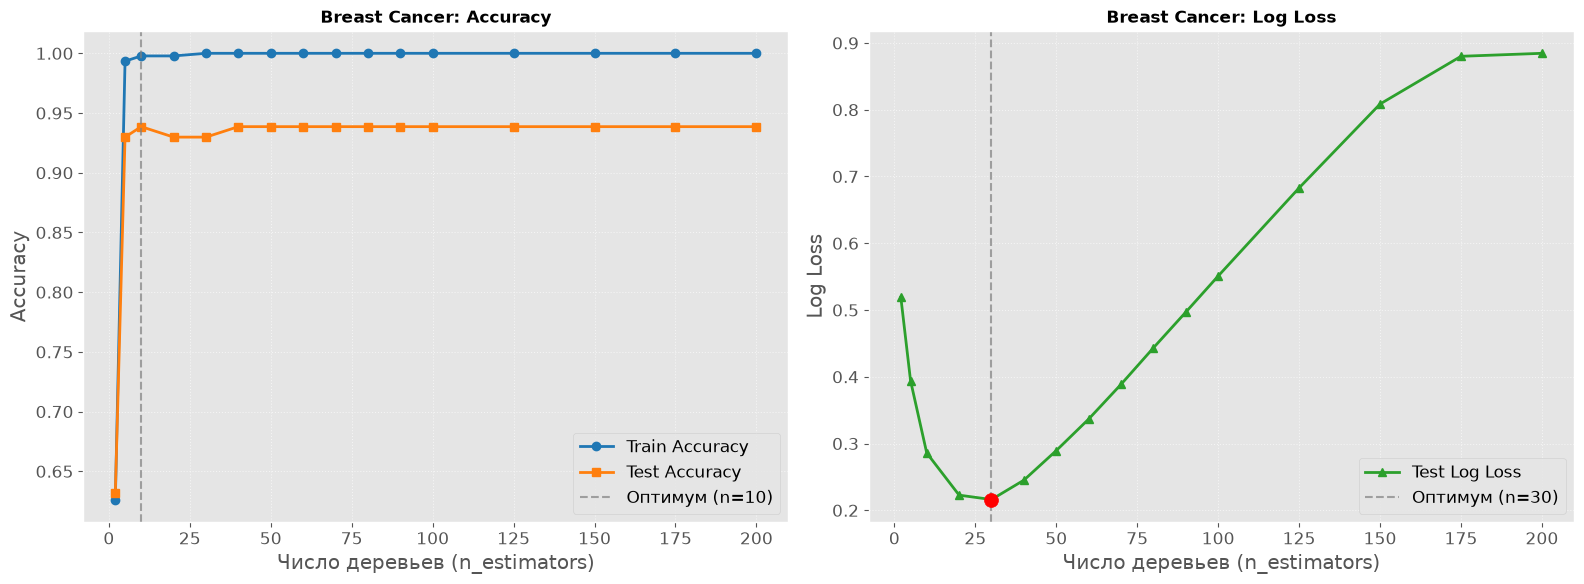

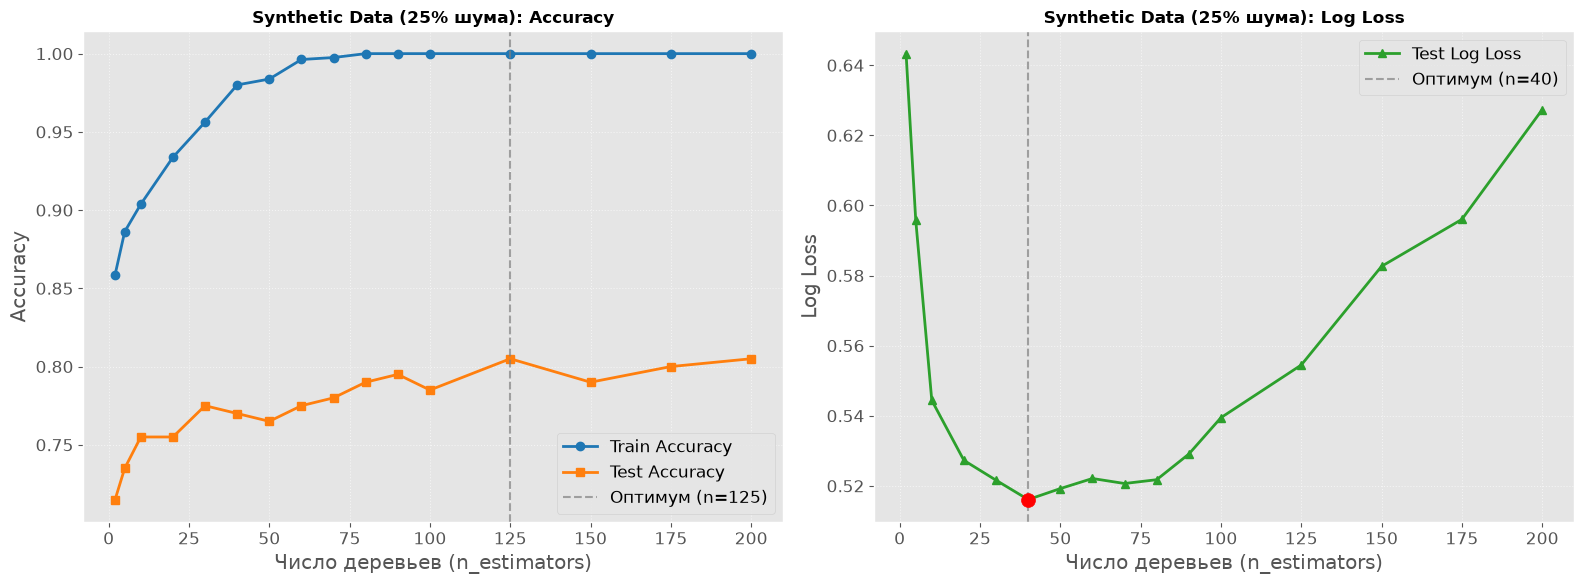

In [3]:
def plot_learning_curves(df_results, title_prefix):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # график 1: accuracy
    ax1.plot(df_results['n_estimators'], df_results['train_acc'], 
             marker='o', label='Train Accuracy', color='#1f77b4', linewidth=2)
    ax1.plot(df_results['n_estimators'], df_results['test_acc'], 
             marker='s', label='Test Accuracy', color='#ff7f0e', linewidth=2)
    
    best_idx = df_results['test_acc'].idxmax()
    best_n = df_results.loc[best_idx, 'n_estimators']
    ax1.axvline(x=best_n, color='gray', linestyle='--', alpha=0.7, label=f'Оптимум (n={best_n})')
    
    ax1.set_title(f'{title_prefix}: Accuracy', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Число деревьев (n_estimators)')
    ax1.set_ylabel('Accuracy')
    ax1.legend()
    ax1.grid(True, linestyle=':', alpha=0.6)

    # график 2: log loss
    best_loss_idx = df_results['test_logloss'].idxmin()
    best_loss_n = df_results.loc[best_loss_idx, 'n_estimators']
    
    ax2.plot(df_results['n_estimators'], df_results['test_logloss'], 
             marker='^', label='Test Log Loss', color='#2ca02c', linewidth=2)
    ax2.axvline(x=best_loss_n, color='gray', linestyle='--', alpha=0.7, 
                label=f'Оптимум (n={best_loss_n})')
    ax2.scatter(best_loss_n, df_results.loc[best_loss_idx, 'test_logloss'], color='red', s=100, zorder=5)
    
    ax2.set_title(f'{title_prefix}: Log Loss', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Число деревьев (n_estimators)')
    ax2.set_ylabel('Log Loss')
    ax2.legend()
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()


plot_learning_curves(df_results_bc, 'Breast Cancer')
plot_learning_curves(df_results_syn, 'Synthetic Data (25% шума)')

По построенным графикам можно сделать следующие наблюдения:

1. **Феномен плато в `Accuracy`.** На обоих датасетах метрика Accuracy на тестовой выборке быстро достигает своего максимума (в районе 10–20 деревьев) и выходит на плато. Это связано с тем, что Accuracy - дискретная метрика. Даже если модель становится излишне самоуверенной, но продолжает угадывать класс (порог 0.5), метрика не падает.
2. **U-образная кривая `Log Loss`.** Гораздо более чувствительной метрикой оказался Log Loss. На обоих графиках отчетливо виден минимум, после которого Loss начинает резко расти:
   * Для **Breast Cancer** оптимум наступает на **30 деревьях**, после чего Loss вырастает почти в 4 раза к 200-му дереву.
   * Для **Synthetic Data** оптимум наступает на **40 деревьях**, после чего Loss также начинает уверенно расти.
   Это происходит потому, что с увеличением числа деревьев модель начинает переобучаться, запоминать шум и выдавать крайне самоуверенные, но неверные вероятности, что строго наказывается логарифмической функцией потерь.
3. **Несовпадение оптимумов.** На обоих датасетах оптимумы по Accuracy и Log Loss не совпадают. 
   * На **Breast Cancer** максимум Accuracy достигается уже на 10 деревьях, в то время как минимум Log Loss - только на 30. 
   * На **синтетическом датасете** плато Accuracy наступает на 20 деревьях, а минимум Log Loss - на 80. 
   Это еще раз подчеркивает, что Accuracy "не видит" излишнюю самоуверенность модели до тех пор, пока она не начнет ошибаться в классах.


**Вывод:** При выборе гиперпараметра `n_estimators` (и при настройке ранней остановки) **следует ориентироваться на Log Loss**, так как она лучше отражает обобщающую способность модели и вовремя сигнализирует о начале переобучения.

## 4. Анализ времени обучения при росте числа деревьев

Помимо качества классификации, важнейшим аспектом применения ансамблевых методов является вычислительная сложность. Градиентный бустинг строит деревья последовательно, поэтому с увеличением `n_estimators` время обучения должно расти. 

В этом разделе визуализируем зависимость времени обучения от числа деревьев для обоих датасетов. Для этого проведем отдельный эксперимент с расширенным диапазоном - до 2000 деревьев. 

In [4]:
n_estimators_time = [10, 50, 100, 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000]

def measure_training_time(X_train, y_train, dataset_name):
    times = []
    
    for n in n_estimators_time:
        
        model = GradientBoostingClassifier(
            n_estimators=n, 
            learning_rate=0.1, 
            max_depth=5, 
            random_state=42
        )
        
        start_time = time.perf_counter()
        model.fit(X_train, y_train)
        fit_time = time.perf_counter() - start_time
        
        times.append(fit_time)
        
    return times

print("Обучение моделей на Breast Cancer...")
times_bc = measure_training_time(X_train_bc, y_train_bc, "Breast Cancer")

print("Обучение моделей на Synthetic Data...")
times_syn = measure_training_time(X_train_syn, y_train_syn, "Synthetic Data")

print("Готово!")

Обучение моделей на Breast Cancer...
Обучение моделей на Synthetic Data...
Готово!


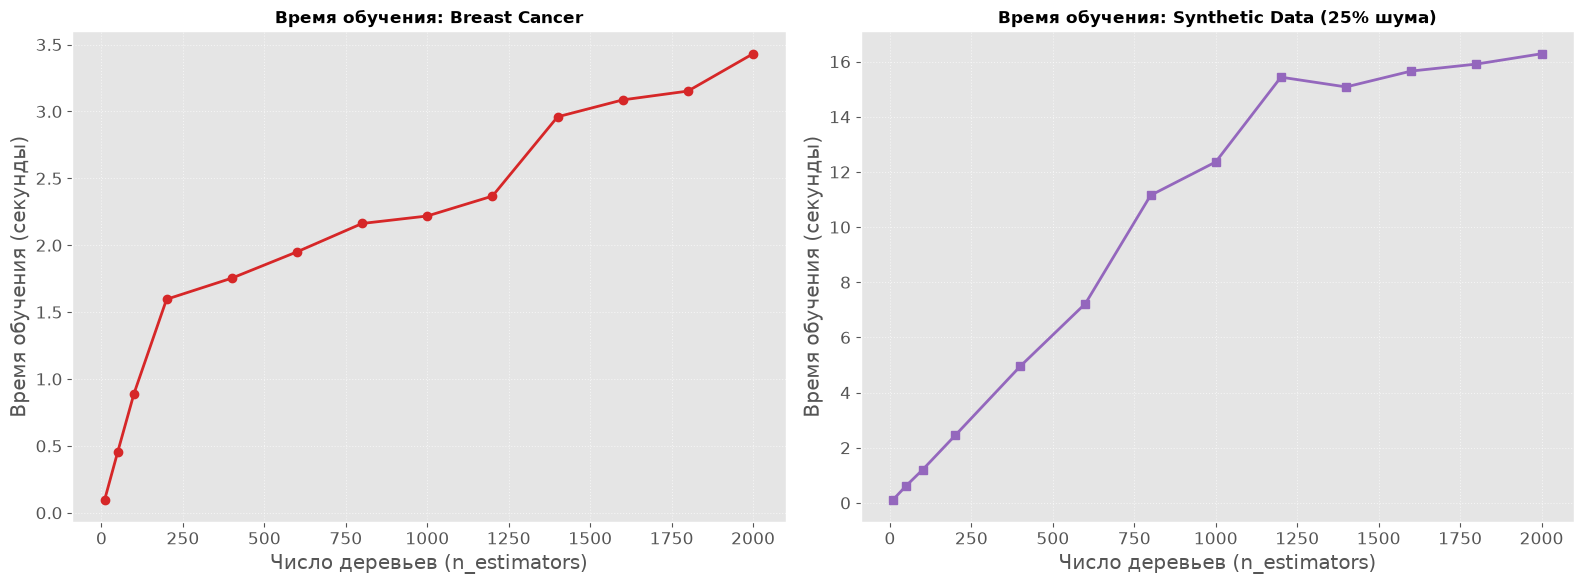

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# график для breast cancer
ax1.plot(n_estimators_time, times_bc, marker='o', color='#d62728', linewidth=2)
ax1.set_title('Время обучения: Breast Cancer', fontsize=12, fontweight='bold')
ax1.set_xlabel('Число деревьев (n_estimators)')
ax1.set_ylabel('Время обучения (секунды)')
ax1.grid(True, linestyle=':', alpha=0.6)

# график для synthetic data
ax2.plot(n_estimators_time, times_syn, marker='s', color='#9467bd', linewidth=2)
ax2.set_title('Время обучения: Synthetic Data (25% шума)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Число деревьев (n_estimators)')
ax2.set_ylabel('Время обучения (секунды)')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

На графиках зависимости времени обучения от `n_estimators` видно, что рост времени не является строго линейным. 

Это объясняется внутренней механикой градиентного бустинга:сначала ошибка модели (псевдоостатки) велика, поэтому алгоритм строит более сложные деревья (в рамках заданной максимальной глубины `max_depth=5`). По мере добавления деревьев модель все лучше подгоняется под данные, ошибка (псевдоостатки) становится маленькой. Алгоритм начинает строить более простые деревья (с меньшим числом листьев), и время на их построение сокращается. Поэтому графики становятся более пологими.

## 5. Механизм ранней остановки (Early Stopping)

В предыдущих пунктах мы убедились, что бесконтрольное увеличение `n_estimators` приводит к переобучению и неоправданной трате времени.

Для решения этой проблемы в `sklearn` реализован механизм Early Stopping. Применим его к нашим датасетам и посмотрим, на каком количестве деревьев алгоритм остановится. Параметр `n_iter_no_change` зададим равным 10.

In [6]:
def train_with_early_stopping(X_train, y_train, X_test, y_test, dataset_name):
    print(dataset_name)
    
    model_es = GradientBoostingClassifier(
        n_estimators=1000, 
        learning_rate=0.1, 
        max_depth=5, 
        n_iter_no_change=10, #включаем early stopping с n_iter_no_change
        random_state=42
    )
    
    start_time = time.perf_counter()
    model_es.fit(X_train, y_train)
    fit_time_es = time.perf_counter() - start_time
    
    y_test_pred = model_es.predict(X_test)
    y_test_proba = model_es.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_test_pred)
    loss = log_loss(y_test, y_test_proba)
    
    actual_trees = model_es.n_estimators_
    
    print(f"Задано деревьев (max): 1000")
    print(f"Реально построено: {actual_trees}")
    print(f"Время обучения: {fit_time_es:.3f} с")
    print(f"Test Accuracy: {acc:.4f}")
    print(f"Test Log Loss: {loss:.4f}\n")
    
    return model_es, actual_trees, fit_time_es

# breast cancer
model_bc_es, trees_bc, time_bc_es = train_with_early_stopping(
    X_train_bc, y_train_bc, X_test_bc, y_test_bc, 
    "Breast Cancer (Early Stopping)"
)

# synthetic data
model_syn_es, trees_syn, time_syn_es = train_with_early_stopping(
    X_train_syn, y_train_syn, X_test_syn, y_test_syn, 
    "Synthetic Data (Early Stopping)"
)

Breast Cancer (Early Stopping)
Задано деревьев (max): 1000
Реально построено: 24
Время обучения: 0.183 с
Test Accuracy: 0.9211
Test Log Loss: 0.2389

Synthetic Data (Early Stopping)
Задано деревьев (max): 1000
Реально построено: 36
Время обучения: 0.406 с
Test Accuracy: 0.7800
Test Log Loss: 0.5202



Результаты работы механизма ранней остановки (с параметром `n_iter_no_change=10`) подтверждают его высокую эффективность:

1. **Автоматический выбор `n_estimators`**: 
   * На датасете **Breast Cancer** алгоритм остановился на **24** деревьях (вместо заданных 1000). Это отлично согласуется с ручным экспериментом, где минимум Log Loss был в районе 30 деревьев.
   * На синтетическом датасете алгоритм остановился на **36** деревьях (ручной оптимум был около 40).
2. **Экономия времени.** Обучение заняло всего 0.2 и 0.6 секунды соответственно. Попытка обучить 1000 деревьев заняла бы в разы больше времени.
3. **Защита от переобучения.** Метрика Log Loss осталась близко к минимуму.

**Вывод:** Механизм `Early Stopping` избавляет от необходимости вручную перебирать сетку `n_estimators`, автоматически находит зону оптимума и колоссально экономит вычислительные ресурсы.

## 6. Анализ важности признаков (Feature Importance)

Градиентный бустинг позволяет оценить вклад каждого признака в итоговое предсказание. Важность признака (feature importance) вычисляется на основе того, насколько часто он использовался для разбиения в деревьях и насколько сильно это разбиение улучшало качество модели (снижало impurity).

Сначала посмотрим, как меняется важность признаков на датасете **Breast Cancer** для недообученной, оптимальной и переобученной моделей. 

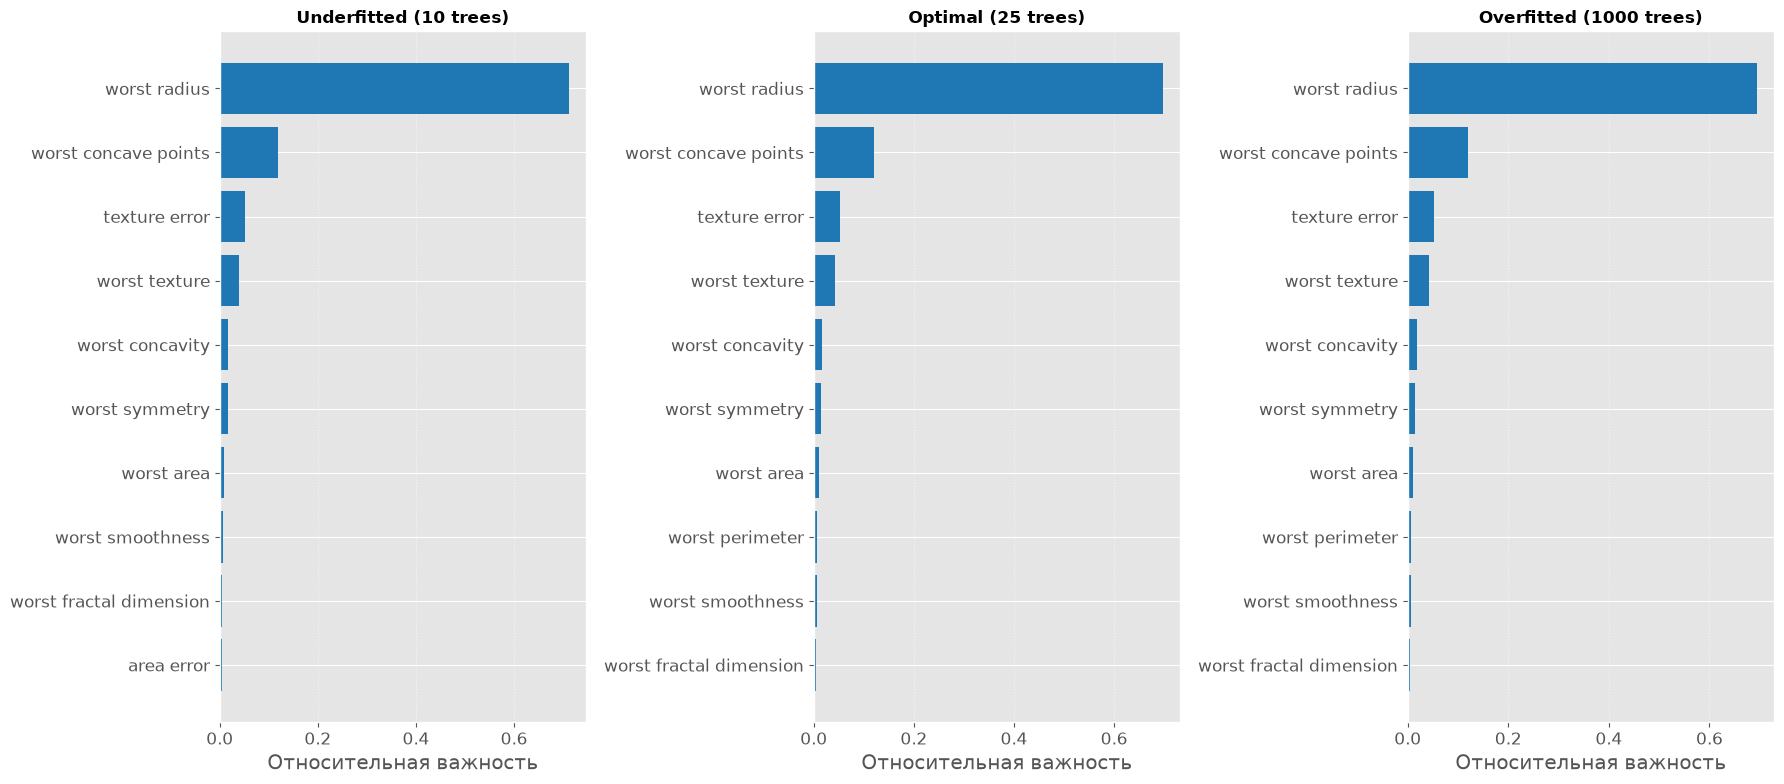

In [7]:
feature_names_bc = data_bc.feature_names

models_bc = {
    'Underfitted (10 trees)': GradientBoostingClassifier(n_estimators=10, max_depth=5, random_state=42),
    'Optimal (25 trees)': GradientBoostingClassifier(n_estimators=25, max_depth=5, random_state=42),
    'Overfitted (1000 trees)': GradientBoostingClassifier(n_estimators=1000, max_depth=5, random_state=42)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, (title, model) in zip(axes, models_bc.items()):
    model.fit(X_train_bc, y_train_bc)
    importances = model.feature_importances_
    indices = np.argsort(importances)[-10:]
    
    ax.barh(range(len(indices)), importances[indices], color='#1f77b4', align='center')
    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(np.array(feature_names_bc)[indices])
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Относительная важность')
    ax.grid(True, linestyle=':', alpha=0.6, axis='x')

plt.tight_layout()
plt.show()

На всех трех диаграммах наиболее важные признаки одинаковы. Признак `worst radius` (худший радиус) является абсолютным лидером. Даже при 1000 деревьев модель не начинает «цепляться» за другие признаки, так как этот сигнал изначально обладает колоссальной разделяющей способностью. 

Теперь проведем этот эксперимент на **синтетических данных с шумом**. 
Мы знаем структуру этих данных:
*   Признаки 0–9: информативные
*   Признаки 10–14: избыточные
*   Признаки 15–19: чистый шум

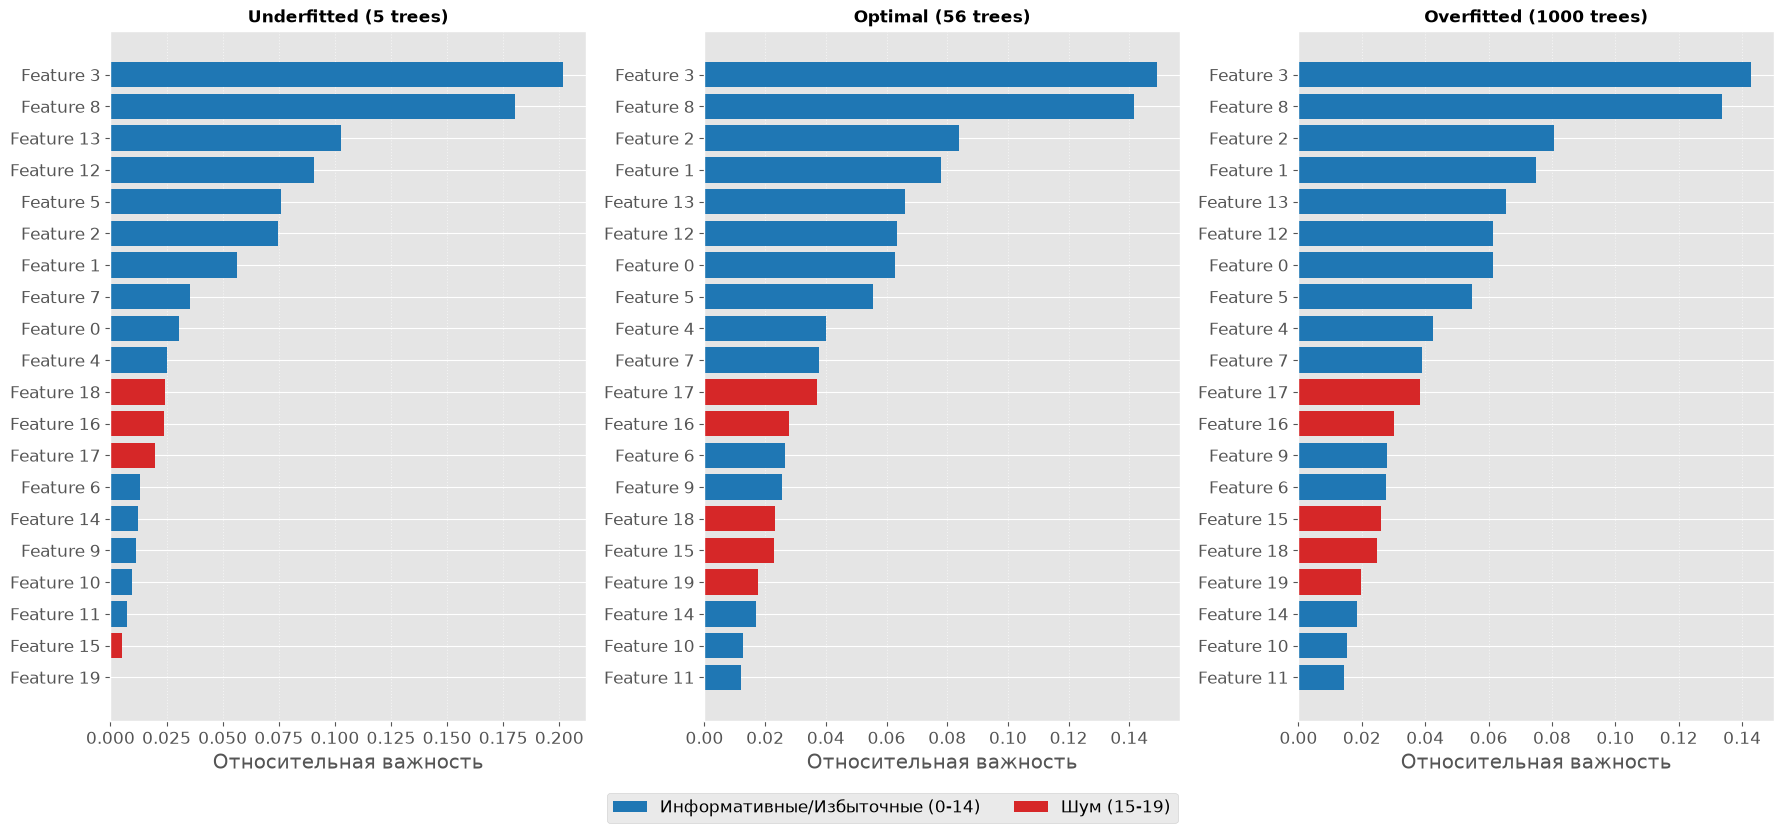

In [8]:
from matplotlib.patches import Patch

feature_names_syn = [f'Feature {i}' for i in range(X_train_syn.shape[1])]

models_syn = {
    'Underfitted (5 trees)': GradientBoostingClassifier(n_estimators=5, max_depth=5, random_state=42),
    'Optimal (56 trees)': GradientBoostingClassifier(n_estimators=56, max_depth=5, random_state=42),
    'Overfitted (1000 trees)': GradientBoostingClassifier(n_estimators=1000, max_depth=5, random_state=42)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, (title, model) in zip(axes, models_syn.items()):
    
    model.fit(X_train_syn, y_train_syn)
    
    importances = model.feature_importances_
    indices = np.argsort(importances)
    
    colors = ['#d62728' if i >= 15 else '#1f77b4' for i in indices]
    
    ax.barh(range(len(indices)), importances[indices], color=colors, align='center')
    ax.set_yticks(range(len(indices)))
    ax.set_yticklabels(np.array(feature_names_syn)[indices])
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Относительная важность')
    ax.grid(True, linestyle=':', alpha=0.6, axis='x')

legend_elements = [Patch(facecolor='#1f77b4', label='Информативные/Избыточные (0-14)'),
                   Patch(facecolor='#d62728', label='Шум (15-19)')]
fig.legend(handles=legend_elements, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.05))

plt.tight_layout()
plt.show()

И на этих данных важность признаков не меняется кардинально. 

**Вывод:** Глобальная важность признаков (Feature Importance) - устойчивая метрика, которая не всегда отражает локальное переобучение. Хотя модель и начинает использовать шум для запоминания данных, её "главные ориентиры" остаются прежними.

## 7. Выводы

В ходе выполнения данной лабораторной работы было исследовано влияние гиперпараметра `n_estimators` (числа базовых моделей) на поведение `GradientBoostingClassifier`.

Основные результаты и выводы:

1. **Влияние на качество (Accuracy).** Метрика accuracy быстро достигает своего потолка (плато) при малом числе деревьев. Из-за своей дискретности она не подходит для тонкой настройки `n_estimators` и не позволяет вовремя заметить начало переобучения.
2. **Влияние на уверенность модели (Log Loss).** Логарифмическая функция потерь (Log Loss) оказалась гораздо более чувствительной. График её зависимости от числа деревьев имеет U-образную форму: сначала Loss падает (модель учится), а затем начинает расти (модель переобучается, становясь излишне самоуверенной).
3. **Время обучения.** С ростом числа деревьев время обучения увеличивается. Обучение 1000 деревьев - это неоправданная трата ресурсов, так как качество на этом этапе уже деградирует.
4. **Эффективность Early Stopping.** Механизм ранней остановки (реализованный через `n_iter_no_change` в sklearn) блестяще справляется с задачей. Он автоматически находит количество деревьев, близкое к минимуму Log Loss, останавливает обучение и экономит время, защищая модель от переобучения.
5. **Анализ Feature Importance.** Эксперимент показал, что глобальная важность признаков остается стабильной даже при переобучении. Хотя модель начинает использовать шум для запоминания данных, наиболее важные признаки остаются неизменными.